In [1]:
from pyprojroot import here
import polars as pl
import cv2
import numpy as np
from typing import Literal
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as ex

In [2]:
# params
path_data = here() / "data"
path_processed = path_data / "processed"
path_raw = path_data / "raw"
path_raw_img = path_raw / "Images"
path_sample_img = path_raw_img / "31_2.jpg"

size_preview = (500, 500)

seed = 123

In [3]:
df = pl.read_csv(path_processed / "labels.csv")
df.head()

Image Name,Patient,Label,Quality Score,SPLIT
str,i64,str,f64,str
"""0_0.jpg""",0,"""GON+""",6.18,"""TRAIN"""
"""1_0.jpg""",1,"""GON+""",5.31,"""TRAIN"""
"""1_1.jpg""",1,"""GON+""",4.37,"""TRAIN"""
"""2_0.jpg""",2,"""GON+""",3.51,"""TRAIN"""
"""2_1.jpg""",2,"""GON+""",4.24,"""TRAIN"""


# Tools

In [4]:
def imshow(input) -> None:
    if type(input) is not np.ndarray:
        _img = cv2.imread(input)
    else:
        _img = input
    _img_resize = cv2.resize(_img, size_preview)
    cv2.imshow("Preview window", _img_resize)
    cv2.waitKey(0)
    cv2.destroyAllWindows()

In [5]:
def imshow_c(input, channel: Literal["B", "G", "R"]) -> None:
    if type(input) is not np.ndarray:
        _img = cv2.imread(input)
    else:
        _img = input
    _img_resize = cv2.resize(_img, size_preview)
    _img_channel = _img_resize[:, :, {"B": 0, "G": 1, "R": 2}[channel]]
    cv2.imshow("Preview window", _img_channel)
    cv2.waitKey(0)
    cv2.destroyAllWindows()

In [6]:
def imshow_2(in1:np.ndarray, in2:np.ndarray) -> None:
    _in1_resize = cv2.resize(in1, size_preview)
    _in2_resize = cv2.resize(in2, size_preview)
    _concat = np.concatenate([_in1_resize, _in2_resize], axis=1)
    cv2.imshow("Preview window", _concat)
    cv2.waitKey(0)
    cv2.destroyAllWindows()

In [7]:
def imshow_3(in1:np.ndarray, in2:np.ndarray, in3:np.ndarray) -> None:
    _in1_resize = cv2.resize(in1, size_preview)
    _in2_resize = cv2.resize(in2, size_preview)
    _in3_resize = cv2.resize(in3, size_preview)
    _concat = np.concatenate([_in1_resize, _in2_resize, _in3_resize], axis=1)
    cv2.imshow("Preview window", _concat)
    cv2.waitKey(0)
    cv2.destroyAllWindows()

# Optic Dics (OD)

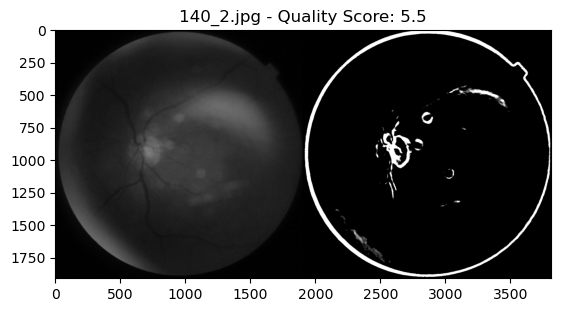

In [8]:
# params
gaussian_blur_kernel: tuple = (51, 51)
sobel_kernel: int = 5
threshold_val = 30

# generate random sample + extract metadata
sample_df = df.filter(pl.col("SPLIT") == "TRAIN").sample(1)
sample_img_name = sample_df.select("Image Name").item()
sample_quality = sample_df.select("Quality Score").item()
sample_path = path_raw_img / sample_img_name

# load and preview
img_ori = cv2.imread(sample_path)

# preprocess
img = img_ori[:, :, 1]  # load and extract green channel
img_blur = cv2.GaussianBlur(img, gaussian_blur_kernel, 0)
sobelx = cv2.Sobel(img_blur, cv2.CV_64F, 1, 0, ksize=sobel_kernel)
sobely = cv2.Sobel(img_blur, cv2.CV_64F, 0, 1, ksize=sobel_kernel)
img_edge = cv2.magnitude(sobelx, sobely)
img_edge = cv2.normalize(img_edge, None, 0, 255, cv2.NORM_MINMAX)
img_edge = np.uint8(img_edge)
img_thres = cv2.threshold(img_edge, threshold_val, 255, cv2.THRESH_BINARY)[1]

# preview
plt.title(f"{sample_img_name} - Quality Score: {sample_quality}")
plt.imshow(cv2.cvtColor(np.hstack([img, img_thres]), cv2.COLOR_BGR2RGB));